In [33]:
%pip install seaborn
#seabornをインストール

Note: you may need to restart the kernel to use updated packages.


In [34]:
#ライブラリをインポート
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [35]:
#Cythonをインストール
%pip install Cython


Note: you may need to restart the kernel to use updated packages.


In [36]:
#sklearnをインストール
import sklearn 
sklearn.set_config(display="text")


In [37]:
#線形モデルをインポート
%pip install scikit-learn
from sklearn.linear_model import LinearRegression as LR
%matplotlib inline

Note: you may need to restart the kernel to use updated packages.


In [38]:
#学習データの読み込み
train = pd.read_csv("train.csv")
#検証用データの読み込み
test = pd.read_csv("test.csv")
#提出用サンプルデータの読み込み
sample = pd.read_csv("sample.csv", header=None)

#データ確認
train.head(5)

,datetime,y,week,soldout,name,kcal,remarks,event,payday,weather,precipitation,temperature
0,2013-11-18,90,月,0,厚切りイカフライ,NaN,NaN,NaN,NaN,快晴,--,19.8
1,2013-11-19,101,火,1,手作りヒレカツ,NaN,NaN,NaN,NaN,快晴,--,17.0
2,2013-11-20,118,水,0,白身魚唐揚げ野菜あん,NaN,NaN,NaN,NaN,快晴,--,15.5
3,2013-11-21,120,木,1,若鶏ピリ辛焼,NaN,NaN,NaN,NaN,快晴,--,15.2
4,2013-11-22,130,金,1,ビッグメンチカツ,NaN,NaN,NaN,NaN,快晴,--,16.1


In [39]:
test.head()

,datetime,week,soldout,name,kcal,remarks,event,payday,weather,precipitation,temperature
0,2014-10-1,水,1,メンチカツ,420.0,NaN,NaN,NaN,雨,0,20.2
1,2014-10-2,木,0,バーベキューチキン,415.0,NaN,NaN,NaN,曇,--,23.9
2,2014-10-3,金,0,豚肉のマスタード焼き,405.0,NaN,NaN,NaN,晴れ,--,28.7
3,2014-10-6,月,1,麻婆春雨,400.0,NaN,NaN,NaN,雨,0.5,21.5
4,2014-10-7,火,0,厚揚げ肉みそ炒め,430.0,NaN,NaN,NaN,晴れ,--,22.1


In [40]:
#データ分離用のフラグを立てる
train["fig"] =1
test["fig"] =0


In [41]:
#trainとtestを結合する
all_data = pd.concat([train,test],axis=0,sort=False)
all_data.head()

,datetime,y,week,soldout,name,kcal,remarks,event,payday,weather,precipitation,temperature,fig
0,2013-11-18,90.0,月,0,厚切りイカフライ,NaN,NaN,NaN,NaN,快晴,--,19.8,1
1,2013-11-19,101.0,火,1,手作りヒレカツ,NaN,NaN,NaN,NaN,快晴,--,17.0,1
2,2013-11-20,118.0,水,0,白身魚唐揚げ野菜あん,NaN,NaN,NaN,NaN,快晴,--,15.5,1
3,2013-11-21,120.0,木,1,若鶏ピリ辛焼,NaN,NaN,NaN,NaN,快晴,--,15.2,1
4,2013-11-22,130.0,金,1,ビッグメンチカツ,NaN,NaN,NaN,NaN,快晴,--,16.1,1


In [42]:
#欠損数、型を確認する
all_data.info()

<class 'pandas.DataFrame'>
Index: 247 entries, 0 to 39
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   datetime       247 non-null    str    
 1   y              207 non-null    float64
 2   week           247 non-null    str    
 3   soldout        247 non-null    int64  
 4   name           247 non-null    str    
 5   kcal           202 non-null    float64
 6   remarks        28 non-null     str    
 7   event          17 non-null     str    
 8   payday         12 non-null     float64
 9   weather        247 non-null    str    
 10  precipitation  247 non-null    str    
 11  temperature    247 non-null    float64
 12  fig            247 non-null    int64  
dtypes: float64(4), int64(2), str(7)
memory usage: 27.0 KB


In [43]:
#データの概要を知る
train.describe()

,y,soldout,kcal,payday,temperature,fig
count,207.000000,207.000000,166.000000,10.0,207.000000,207.0
mean,86.623188,0.449275,404.409639,1.0,19.252174,1.0
std,32.882448,0.498626,29.884641,0.0,8.611365,0.0
min,29.000000,0.000000,315.000000,1.0,1.200000,1.0
25%,57.000000,0.000000,386.000000,1.0,11.550000,1.0
50%,78.000000,0.000000,408.500000,1.0,19.800000,1.0
75%,113.000000,1.000000,426.000000,1.0,26.100000,1.0
max,171.000000,1.000000,462.000000,1.0,34.600000,1.0


<Axes: >

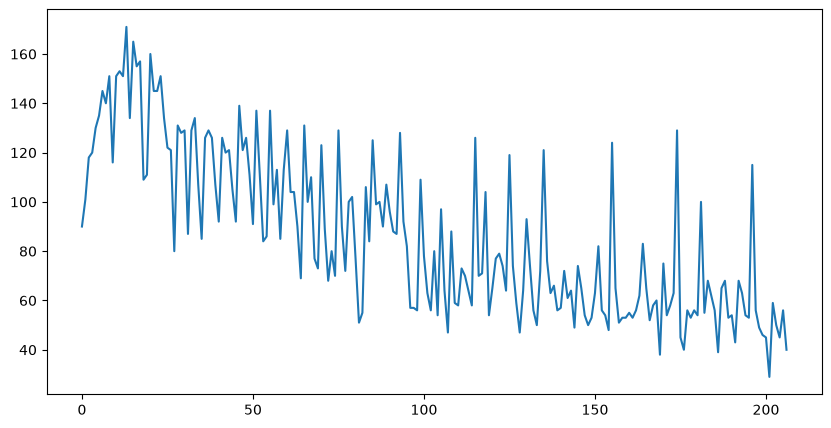

In [44]:
#売り上げのグラフ化
train["y"].plot(figsize=(10,5))

In [45]:
#グラフ化して、売り上げに影響を与える要素を確認する
fig, ax = plt.subplots(2,2,figsize=(12.7))
sns.boxplot(x="week",y="y",data=train,ax=ax[0][0])
sns.boxplot(x="weather",y="y",data=train,ax=ax[0][1])
sns.boxplot(x="remarks",y="y",data=train,ax=ax[1][0])
ax[0][1].set_xticklabels(ax[0][1].get_xticklabels(),rotation=30)
sns.boxplot(x="event",y="y",data=train,ax=ax[1][1])
plt.tight_layout()

TypeError: object of type 'float' has no len()

In [ ]:
#NaNの数を確認する
all_data.isnull().sum()

datetime           0
y                 40
week               0
soldout            0
name               0
kcal              45
remarks          219
event            230
payday           235
weather            0
precipitation      0
temperature        0
fig                0
dtype: int64

In [ ]:
#kcalの欠損値を平均値で補完する
all_data["kcal"] = all_data["kcal"].fillna(all_data["kcal"].mean())
all_data.isnull().sum()

datetime           0
y                 40
week               0
soldout            0
name               0
kcal               0
remarks          219
event            230
payday           235
weather            0
precipitation      0
temperature        0
fig                0
dtype: int64

In [ ]:
#補完の確認
all_data["kcal"].head()

0    407.381188
1    407.381188
2    407.381188
3    407.381188
4    407.381188
Name: kcal, dtype: float64

In [ ]:
#paydayの有無を確認する
print(train.payday.unique())
all_data.loc[~all_data["payday"].isnull(),["week","payday"]]

[nan  1.]


,week,payday
16,火,1.0
31,金,1.0
51,月,1.0
70,月,1.0
92,木,1.0
110,金,1.0
132,火,1.0
154,木,1.0
174,金,1.0
194,水,1.0


In [ ]:
#paydayの欠損値を0で補完する
all_data["payday"] = all_data["payday"].fillna(0)
all_data["payday"].unique()

array([0., 1.])

In [ ]:
#降水量の前処理
# 降水量が--の時
all_data[all_data["precipitation"]=="--"]["weather"].unique()

<StringArray>
['快晴', '曇', '晴れ', '薄曇']
Length: 4, dtype: str

In [ ]:
#降水量が0の時
all_data[all_data["precipitation"]=="0"]["weather"].unique()

<StringArray>
['雨', '曇', '雷電', '薄曇']
Length: 4, dtype: str

In [ ]:
#降水量に数値が入っているとき
all_data[~(all_data["precipitation"]=="0") & ~(all_data["precipitation"]=="--")]["weather"].unique()


<StringArray>
['曇', '雨', '雪']
Length: 3, dtype: str

In [ ]:
#precipitation_flg(カテゴリ変数)を作成する
all_data["precipitation_flg"]="悪い"
all_data.loc[(all_data["precipitation"]=="\--"),"precipitation_flg"]="良い"
all_data.loc[(all_data["precipitation"]=="0"),"precipitation_flg"]="やや悪い"


<>:3: SyntaxWarning: "\-" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\-"? A raw string is also an option.
<>:3: SyntaxWarning: "\-" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\-"? A raw string is also an option.
C:\Users\NDY13\AppData\Local\Temp\ipykernel_14548\3952447809.py:3: SyntaxWarning: "\-" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\-"? A raw string is also an option.
  all_data.loc[(all_data["precipitation"]=="\--"),"precipitation_flg"]="良い"


In [ ]:
#文字列を数的データに変える（量的変数）
all_data["precipitation"] = all_data["precipitation"].replace("--",-1)